Plotting landing sites.

Source: Wueller et al. (2026), JGR Planets, doi:10.1029/2025JE009434.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lunarmag import svm_map, svm_field, project, globe, tsu

/Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Store SVM field at surface and at 30 km:

In [2]:
maps = {}
for alt in (0.0, 30.0):
    lats, lons, Be, Bn, Br, Bt = svm_map(alt=alt, lmax=450)
    maps[alt] = {'Br': Br, 'Bh': np.hypot(Be, Bn)}

Load landing sites:

In [8]:
# Wueller et al. (2026), JGR Planets, doi:10.1029/2025JE009434, Table A1
# Each entry: (lon, lat) in degrees; table lists (lat, lon), order swapped here.
# Longitudes signed (negative = west); converted to 0-360 °E below.
sites = {
    'Peak near Cabeus B': [            # PCB01-05
        (-69.9830, -83.7630), (-67.6340, -83.6320), (-68.2010, -83.5630),
        (-67.6650, -83.3690), (-71.9420, -83.5390)],
    'Haworth': [                       # HW01-10, HW_K2023
        (-20.5140, -86.7680), (-21.7190, -86.8080), (-19.8930, -86.8600),
        (-21.4730, -86.5680), (-30.5480, -86.6620), (-24.2400, -87.0500),
        (-23.0200, -86.9320), (-25.8090, -86.9240), (-26.0750, -86.6230),
        (-14.8760, -86.5270), (-24.2540, -86.9900)],
    'Malapert Massif': [               # Mons Malapert in the paper: MMA01-04, MMA_K2023
        (-0.9440, -85.9420), (3.3820, -86.0150), (-3.2780, -85.9580),
        (-0.4590, -86.3100), (2.0560, -85.9920)],
    'Mons Mouton Plateau': [           # MMP01-11
        (26.7100, -85.1110), (24.8870, -84.8050), (31.1530, -84.9680),
        (20.8870, -84.6860), (28.2120, -84.4160), (30.4520, -84.5960),
        (37.3390, -84.6830), (40.8100, -84.2110), (32.8850, -83.6840),
        (25.6420, -84.1380), (36.6720, -84.2690)],
    'Mons Mouton': [                   # MMO01-10
        (31.8510, -85.4160), (29.5490, -85.4810), (30.4060, -85.4090),
        (28.1500, -85.4090), (28.5940, -85.3440), (30.1860, -85.2610),
        (32.9290, -85.1950), (35.7040, -85.5130), (33.0400, -85.4660),
        (31.4900, -85.4610)],
    'Nobile Rim 1': [                  # NR101-109
        (36.9170, -85.2950), (36.8890, -85.2610), (37.5570, -85.5460),
        (37.8750, -85.0170), (37.5550, -85.0720), (36.9860, -85.1560),
        (37.1770, -85.1980), (36.7510, -85.1030), (37.4340, -85.0400)],
    'Nobile Rim 2': [                  # NR201-208, NR2_K2023
        (56.4810, -84.0540), (59.8350, -84.1550), (57.0080, -83.6870),
        (57.6830, -83.7850), (59.0570, -83.6180), (59.2820, -83.7810),
        (59.3260, -83.9180), (57.8110, -83.9060), (59.1970, -84.0740)],
    'de Gerlache Rim 2': [             # dGR201-206, dGR2_K2023 (second "dGR2" section)
        (-68.8650, -88.3890), (-75.0440, -88.0370), (-71.6960, -88.1410),
        (-74.3330, -88.1380), (-62.0740, -88.0650), (-62.0980, -87.9470),
        (-67.8590, -88.4500)],
    'Slater Plain': [                  # SP01-11
        (124.5210, -87.4780), (126.5130, -87.3820), (123.7480, -87.2830),
        (123.0340, -87.1920), (119.7030, -87.1820), (126.1310, -87.0730),
        (127.8570, -87.1310), (130.0540, -87.3270), (133.3440, -87.1840),
        (130.7020, -87.0320), (126.6750, -86.9500)],
}

sites = {k: np.array(v, dtype=float).reshape(-1, 2) for k, v in sites.items()}
for pts in sites.values():
    pts[:, 0] %= 360 #longitudes as 0-360 °E per svm_field

for name, pts in sites.items():
    if len(pts) == 0:
        print(f'{name:20s}  no sites yet')
        continue
    print(f'{name:20s} {len(pts):2d} sites   lat {pts[:, 1].min():7.2f} to {pts[:, 1].max():7.2f}')

Peak near Cabeus B    5 sites   lat  -83.76 to  -83.37
Haworth              11 sites   lat  -87.05 to  -86.53
Malapert Massif       5 sites   lat  -86.31 to  -85.94
Mons Mouton Plateau  11 sites   lat  -85.11 to  -83.68
Mons Mouton          10 sites   lat  -85.51 to  -85.19
Nobile Rim 1          9 sites   lat  -85.55 to  -85.02
Nobile Rim 2          9 sites   lat  -84.16 to  -83.62
de Gerlache Rim 2     7 sites   lat  -88.45 to  -87.95
Slater Plain         11 sites   lat  -87.48 to  -86.95


Plot zoomed south pole maps with sites:

Text(0.5, 0.98, 'SVM crustal field poleward of 82°S, with Artemis III candidate landing sites (Wueller et al. 2026)')

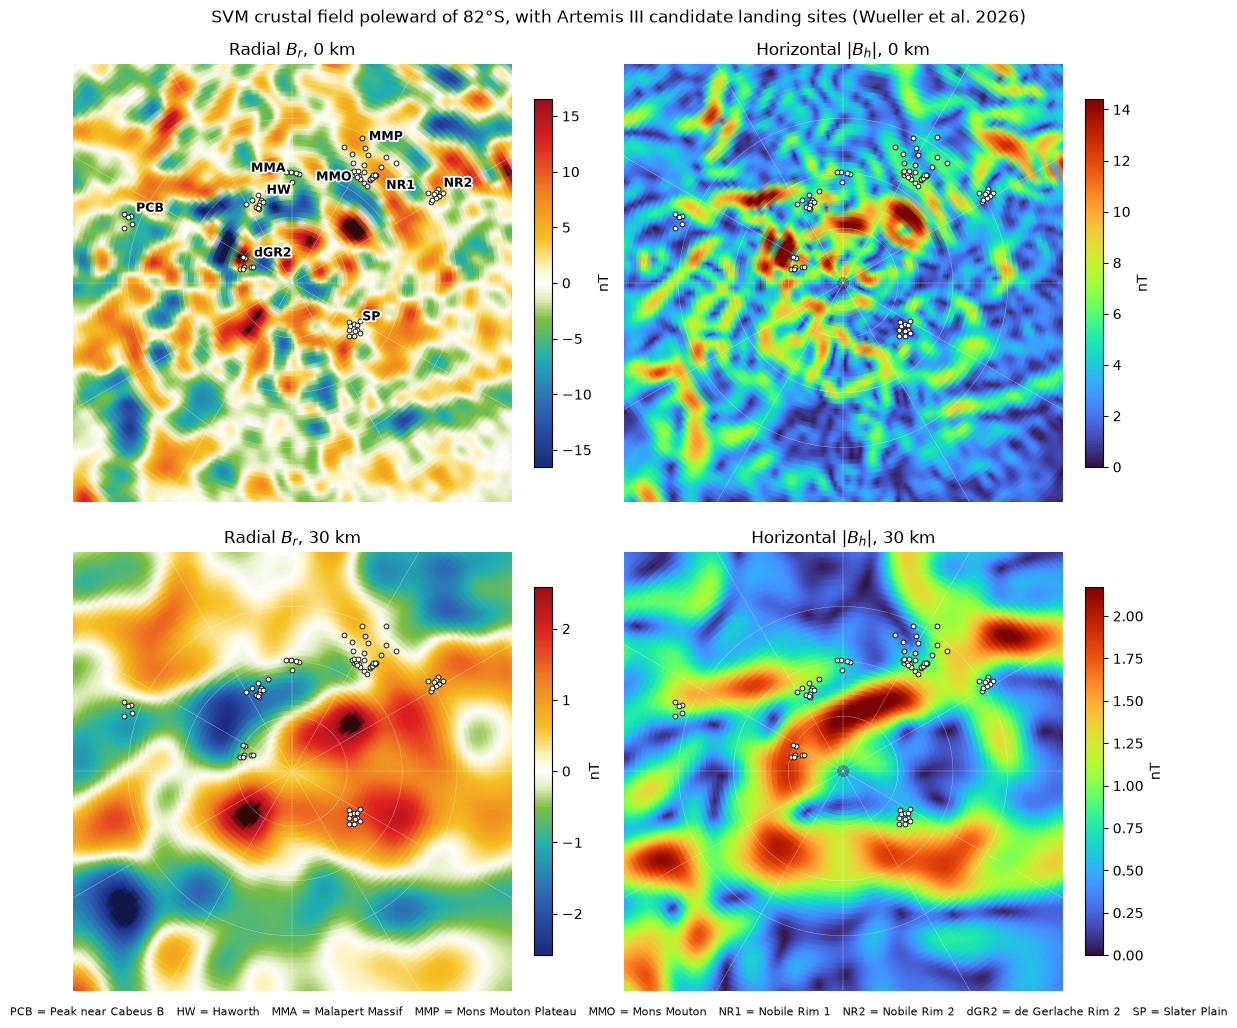

In [10]:
import matplotlib.patheffects as pe

lon0_s = 0.0
r_lim = 2 * np.sin(np.radians(8) / 2)         # Lambert radius of 82°S (8° from the pole)
south = lats < -82                            # colour limits from the plotted region only

codes = {'Peak near Cabeus B': 'PCB', 'Haworth': 'HW', 'Malapert Massif': 'MMA',
         'Mons Mouton Plateau': 'MMP', 'Mons Mouton': 'MMO', 'Nobile Rim 1': 'NR1',
         'Nobile Rim 2': 'NR2', 'de Gerlache Rim 2': 'dGR2', 'Slater Plain': 'SP'}
offsets = {'MMP': (0, 10), 'MMO': (-30, -4), 'NR1': (10, -8), 'MMA': (-30, 2)}   # points; tune by eye
halo = [pe.withStroke(linewidth=2.5, foreground='w')]

def zoom_south(ax, field, label=False, **kw):
    pc = globe(ax, lats, lons, field, lon0_s, -90, lambert=True, lat_lines=(-84, -86, -88), **kw)
    ax.set_xlim(-r_lim, r_lim); ax.set_ylim(-r_lim, r_lim)
    for name, pts in sites.items():
        if len(pts) == 0:
            continue
        x, y, _ = project(pts[:, 0], pts[:, 1], lon0_s, -90, lambert=True)
        ax.plot(x, y, 'o', ms=3.5, mfc='w', mec='k', mew=0.6)
        if label:
            code = codes[name]
            ax.annotate(code, (x.mean(), y.mean()), xytext=offsets.get(code, (6, 6)),
                        textcoords='offset points', fontsize=9, fontweight='bold', path_effects=halo)
    return pc

fig, axs = plt.subplots(2, 2, figsize=(11, 10), layout='constrained')
for row, alt in enumerate((0.0, 30.0)):
    Br, Bh = maps[alt]['Br'], maps[alt]['Bh']
    vr = np.percentile(np.abs(Br[south]), 99)
    vh = np.percentile(Bh[south], 99)
    pc = zoom_south(axs[row, 0], Br, label=(row == 0), cmap=tsu, vmin=-vr, vmax=vr)
    fig.colorbar(pc, ax=axs[row, 0], shrink=0.8, label='nT')
    pc = zoom_south(axs[row, 1], Bh, cmap='turbo', vmin=0, vmax=vh)
    fig.colorbar(pc, ax=axs[row, 1], shrink=0.8, label='nT')
    axs[row, 0].set_title(f'Radial $B_r$, {alt:.0f} km'); axs[row, 1].set_title(f'Horizontal $|B_h|$, {alt:.0f} km')

fig.text(0.5, -0.01, '   '.join(f'{c} = {n}' for n, c in codes.items()), ha='center', fontsize=8)
fig.suptitle('SVM crustal field poleward of 82°S, with Artemis III candidate landing sites (Wueller et al. 2026)')

Field at each region:

In [11]:
rows = []
for name, pts in sites.items():
    if len(pts) == 0:
        continue
    for alt in (0.0, 30.0):
        Be_, Bn_, Br_ = svm_field(pts[:, 0], pts[:, 1], np.full(len(pts), alt))
        B = np.sqrt(Be_**2 + Bn_**2 + Br_**2)
        rows.append({'region': name, 'alt_km': alt, 'n_sites': len(pts),
                     'B_min_nT': B.min(), 'B_max_nT': B.max()})
print(pd.DataFrame(rows))

                 region  alt_km  n_sites  B_min_nT   B_max_nT
0    Peak near Cabeus B     0.0        5  3.122054   6.358557
1    Peak near Cabeus B    30.0        5  1.308906   1.379578
2               Haworth     0.0       11  3.137250   9.039951
3               Haworth    30.0       11  1.304573   1.953703
4       Malapert Massif     0.0        5  4.554559   7.154105
5       Malapert Massif    30.0        5  0.727169   0.976731
6   Mons Mouton Plateau     0.0       11  3.211149   7.614808
7   Mons Mouton Plateau    30.0       11  0.440035   1.306248
8           Mons Mouton     0.0       10  5.882162   7.217637
9           Mons Mouton    30.0       10  0.700514   1.029225
10         Nobile Rim 1     0.0        9  6.343158   7.260109
11         Nobile Rim 1    30.0        9  0.950495   1.108279
12         Nobile Rim 2     0.0        9  1.616704   8.404780
13         Nobile Rim 2    30.0        9  1.211628   1.376509
14    de Gerlache Rim 2     0.0        7  7.268120  24.374936
15    de

Limitations:

- Topography: for surface map, values on raised structures are overestimates 
- Resolution limited to approx 12 km for l_max = 450